# 문자열에서 검색 점수까지, 그리고 분류로

**문서·질의 → 토큰·어휘 → TF·DF·IDF → TF-IDF·정규화 → 코사인·순위**를
두 문서로 계산한 뒤 같은 모듈을 실제 게시글 검색과 분류에 연결한다.
Python 변수·반복문·배열에서 출발한다. 먼저 숫자를 예상하고 실행 결과를 읽는다.

A4-1에서 `uv sync --group dev` 후 `.venv`를 커널로 선택하고 위에서 아래로 실행한다.
`uv run --group dev python tools/build_learning_notebook.py --execute`로 새 커널 실행도 가능하다.
실제 데이터 캐시가 없으면 다운로드한다. C 후보 3개 × 5-fold 분류는 수 분 걸릴 수 있다.
기존 `outputs/`를 읽어 이전 조건과 비교하며 덮어쓰지 않는다.

[HTML](../study/a4-1.html)은 설정을 바꾸는 계산기·브라우저 시연에,
이 노트북은 Python의 중간 배열과 학습 경계 확인에 쓴다.
HTML의 분류 표는 이전 CV 조건의 저장 결과다. 새 CV 수치는 이 노트북에서 확인한다.

In [1]:
from pathlib import Path
import sys
import json
import platform
import numpy as np
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
assert (root/'src/tfidf.py').is_file(), 'A4-1 또는 notebooks에서 실행하세요.'
sys.path.insert(0, str(root))
from src.preprocess import clean, tokenize, normalize, remove_stopwords, preprocess
from src.tfidf import TfidfVectorizerNP, term_frequency
from src.search import SearchEngine, cosine_similarity, top_k
from src.data import Corpus, load_corpus, train_test_indices
from src.classify import run_classification
from src.experiments import verify_against_sklearn, verify_cosine, bow_limits, benchmark_index
thread_limit = threadpool_limits(limits=2)
np.set_printoptions(precision=6, suppress=True)
print('Python', platform.python_version(), 'NumPy', np.__version__, 'sklearn', sklearn.__version__)

def table(headers, rows):
    lines = ['| ' + ' | '.join(map(str, headers)) + ' |',
             '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    for row in rows:
        lines.append('| ' + ' | '.join(map(str, row)) + ' |')
    display(Markdown('\n'.join(lines)))

Python 3.12.13 NumPy 2.5.4 sklearn 1.9.1


## 1. 입력에서 토큰까지

문서 d0은 `Space space orbit!`, d1은 `Goalie orbit.`, 질의는 `SPACE orbit unknown`이다.
d0의 space는 두 번 등장한다. 빈도 TF와 출현 문서 수 DF가 어떻게 다른지 예상해 보자.
정제 → 토큰화 → 표기 통합 → 불용어 제거는 영어 규칙이다. 한국어 형태소 분석은 지원하지 않는다.

In [2]:
documents = ['Space space orbit!', 'Goalie orbit.']
query = 'SPACE orbit unknown'
tokens = []
for i, text in enumerate(documents):
    cleaned = clean(text)
    pieces = tokenize(cleaned)
    normalized = normalize(pieces)
    kept = remove_stopwords(normalized)
    tokens.append(kept)
    print('d', i, ':', repr(text), '→', repr(cleaned), '→', pieces, '→', normalized, '→', kept)
query_tokens = preprocess(query)
print('질의:', repr(query), '→', query_tokens)

d 0 : 'Space space orbit!' → 'space space orbit' → ['space', 'space', 'orbit'] → ['space', 'space', 'orbit'] → ['space', 'space', 'orbit']
d 1 : 'Goalie orbit.' → 'goalie orbit' → ['goalie', 'orbit'] → ['goalie', 'orbit'] → ['goalie', 'orbit']
질의: 'SPACE orbit unknown' → ['space', 'orbit', 'unknown']


## 2. 같은 열에 같은 단어 놓기

어휘는 알파벳순 `[goalie, orbit, space]`. 한 행은 문서, 한 열은 단어다.
첫 예는 `min_df=1, max_df=1.0`으로 세 단어를 모두 남긴다.
실제 검색 기본값 `min_df=5, max_df=0.5`와 다르다. 문서 두 개에 5를 쓰면 열이 사라진다.
`max_df=1.0`은 전체 문서 비율이고 정수 `1`은 한 문서라는 차이도 주의한다.

In [3]:
terms = sorted(set(tokens[0] + tokens[1]))
vocabulary = {}
for column, term in enumerate(terms):
    vocabulary[term] = column
counts = np.zeros((len(tokens), len(terms)), dtype=np.float64)
for row, document_tokens in enumerate(tokens):
    for term in document_tokens:
        counts[row, vocabulary[term]] += 1
print('단어 → 열 번호:', vocabulary)
print('빈도 행렬 shape / dtype:', counts.shape, counts.dtype)
table(['문서'] + terms, [['d0'] + counts[0].tolist(), ['d1'] + counts[1].tolist()])

단어 → 열 번호: {'goalie': 0, 'orbit': 1, 'space': 2}
빈도 행렬 shape / dtype: (2, 3) float64


| 문서 | goalie | orbit | space |
| --- | --- | --- | --- |
| d0 | 0.0 | 1.0 | 2.0 |
| d1 | 1.0 | 1.0 | 0.0 |

## 3. TF와 DF를 구별하고 IDF 곱하기

기본 TF는 원래 빈도다. DF는 `(counts > 0)`을 문서 방향(axis=0)으로 합친다.
space 빈도 합은 2지만 DF는 1이다. 기본 IDF는 자연로그 `ln((N+1)/(DF+1))+1`.
orbit은 두 문서 모두에 있어 IDF=1, 나머지는 약 1.405465다.
분수의 +1은 smoothing, 바깥 +1은 흔한 단어도 가중치 1을 남기는 역할이다.

In [4]:
tf = counts.copy()
presence = counts > 0
df = presence.sum(axis=0)
idf = np.log((len(tokens) + 1) / (df + 1)) + 1
weighted = tf * idf
print('출현 여부:\n', presence)
table(['단어', '총빈도', 'DF', 'IDF'],
      [[term, counts[:, j].sum(), df[j], round(idf[j], 6)] for j, term in enumerate(terms)])
print('TF × IDF (2,3):\n', weighted)

출현 여부:
 [[False  True  True]
 [ True  True False]]


| 단어 | 총빈도 | DF | IDF |
| --- | --- | --- | --- |
| goalie | 1.0 | 1 | 1.405465 |
| orbit | 2.0 | 2 | 1.0 |
| space | 2.0 | 1 | 1.405465 |

TF × IDF (2,3):
 [[0.       1.       2.81093 ]
 [1.405465 1.       0.      ]]


## 4. 행마다 L2 길이로 나누기

`[0,1,2.810930]`의 길이는 `sqrt(1²+2.810930²)`다. 길이로 나누면
`[0,0.335176,0.942156]` 부근이 된다. 0벡터는 그대로 0으로 둔다.
라이브러리에는 첫 계산을 맡기지 않고 여기서 계산한 뒤 기존 구현 및 sklearn과 대조한다.

In [5]:
lengths = np.sqrt((weighted ** 2).sum(axis=1))
safe_lengths = np.where(lengths > 0, lengths, 1)
document_vectors = weighted / safe_lengths[:, None]
print('길이 shape:', lengths.shape, '→ 나눌 축:', safe_lengths[:, None].shape)
print('L2 정규화:\n', document_vectors)
vec = TfidfVectorizerNP(min_df=1, max_df=1.0)
module_vectors = vec.fit_transform(tokens)
assert terms == vec.terms_
np.testing.assert_allclose(counts, vec.counts(tokens))
np.testing.assert_allclose(idf, vec.idf_)
np.testing.assert_allclose(document_vectors, module_vectors)
from sklearn.feature_extraction.text import TfidfVectorizer
reference = TfidfVectorizer(analyzer=lambda document: document, dtype=np.float64)
reference_vectors = reference.fit_transform(tokens).toarray()
assert terms == list(reference.get_feature_names_out())
np.testing.assert_allclose(document_vectors, reference_vectors)
print('손계산 · 기존 모듈 · sklearn: 같은 토큰/어휘/설정에서 일치')

길이 shape: (2,) → 나눌 축: (2, 1)
L2 정규화:
 [[0.       0.335176 0.942156]
 [0.814802 0.579739 0.      ]]
손계산 · 기존 모듈 · sklearn: 같은 토큰/어휘/설정에서 일치


## 5. 질의는 fit 없이 transform → 점수 → 순위

unknown은 열이 없어 무시한다. 질의로 IDF를 다시 만들면 문서와 좌표계가 달라진다.
코사인은 같은 열끼리 곱한 합을 두 길이의 곱으로 나눈 값이다.
L2 정규화된 양수 행에서는 내적과 같고, 값은 정답 확률이 아니다.

In [6]:
query_counts = np.zeros(len(terms), dtype=np.float64)
for term in query_tokens:
    if term in vocabulary:
        query_counts[vocabulary[term]] += 1
query_weighted = query_counts * idf
query_length = np.linalg.norm(query_weighted)
query_vector = query_weighted / query_length if query_length > 0 else query_weighted
contributions = document_vectors * query_vector
dots = contributions.sum(axis=1)
denominator = np.linalg.norm(document_vectors, axis=1) * np.linalg.norm(query_vector)
scores = np.divide(dots, denominator, out=np.zeros_like(dots), where=denominator > 0)
order = top_k(scores, 5)
print('질의 빈도:', query_counts, '→ TF-IDF:', query_vector)
table(['문서'] + terms + ['코사인'],
      [['d'+str(i)] + contributions[i].round(6).tolist() + [round(scores[i], 6)] for i in range(2)])
print('양수 점수 순위(문서 위치):', order)
np.testing.assert_allclose(query_vector, vec.transform([query_tokens])[0])
np.testing.assert_allclose(scores, cosine_similarity(query_vector, module_vectors))
print('질의도 기존 transform/코사인과 일치')

질의 빈도: [0. 1. 1.] → TF-IDF: [0.       0.579739 0.814802]


| 문서 | goalie | orbit | space | 코사인 |
| --- | --- | --- | --- | --- |
| d0 | 0.0 | 0.194314 | 0.767671 | 0.961985 |
| d1 | 0.0 | 0.336097 | 0.0 | 0.336097 |

양수 점수 순위(문서 위치): [0 1]
질의도 기존 transform/코사인과 일치


## 6. 경계와 정보 손실도 결과다

빈 문서, 불용어만 있는 문서, 영어 규칙이 제거하는 한국어, 미등록 단어는 0벡터가 된다.
아는 단어라도 상대 문서와 겹친 칸이 없으면 0이다. top-k는 0점을 제외하며
동점은 작은 문서 위치 먼저다. 반환 개수가 k보다 적을 수 있다.

In [7]:
for text in ['', 'the and of', 'zzzzunknown', '한국어 검색', 'goalie', 'space orbit', 'orbit space']:
    q = vec.transform([preprocess(text)])[0]
    s = cosine_similarity(q, module_vectors)
    print(repr(text), '→', preprocess(text), '→', q, '→ 점수', s, '→ 순위', top_k(s, 5))
empty_vector = vec.transform([[]])[0]
assert np.count_nonzero(empty_vector) == 0
assert top_k(np.array([0.7, 0.7, 0.0]), 5).tolist() == [0, 1]
for a, b in [('good team', 'not a good team'), ('space orbit', 'orbit space')]:
    print(repr(a), '/', repr(b), '같은 토큰 빈도?', sorted(preprocess(a)) == sorted(preprocess(b)))

'' → [] → [0. 0. 0.] → 점수 [0. 0.] → 순위 []
'the and of' → [] → [0. 0. 0.] → 점수 [0. 0.] → 순위 []
'zzzzunknown' → ['zzzzunknown'] → [0. 0. 0.] → 점수 [0. 0.] → 순위 []
'한국어 검색' → [] → [0. 0. 0.] → 점수 [0. 0.] → 순위 []
'goalie' → ['goalie'] → [1. 0. 0.] → 점수 [0.       0.814802] → 순위 [1]
'space orbit' → ['space', 'orbit'] → [0.       0.579739 0.814802] → 점수 [0.961985 0.336097] → 순위 [0 1]
'orbit space' → ['orbit', 'space'] → [0.       0.579739 0.814802] → 점수 [0.961985 0.336097] → 순위 [0 1]
'good team' / 'not a good team' 같은 토큰 빈도? True
'space orbit' / 'orbit space' 같은 토큰 빈도? True


## 7. 실제 검색: 원문 일부·토큰·공통 단어·기여도 연결

헤더·서명·인용을 제거한 5개 범주의 자료에서 5토큰 미만을 제외한다.
전체 색인은 검색 대상 모두로 어휘·IDF를 만든다. 이것은 분류 평가의 Train이 아니다.
문서 위치 p, 원래 ID, 범주 번호를 같은 문서에 연결한다. 출력 원문은 짧은 발췌만 본다.

In [8]:
corpus = load_corpus()
engine = SearchEngine(corpus)
print('필터 전/후:', corpus.n_raw, len(corpus))
print('검색 문서 행렬:', engine.matrix.shape, engine.matrix.dtype)
actual_query = 'space shuttle launch'
hits = engine.search(actual_query, topk=5)
table(['순위', '원래 ID', '범주', '코사인'],
      [[rank, h.doc_id, corpus.target_names[corpus.labels[engine.position(h.doc_id)]], round(h.score, 6)]
       for rank, h in enumerate(hits, 1)])
first = hits[0]
position = engine.position(first.doc_id)
print('질의 토큰:', engine.query_tokens(actual_query))
print('1위 원문 발췌:', first.snippet[:160])
print('1위 토큰 앞 24개:', corpus.tokens[position][:24])
ex = engine.explain(actual_query, first.doc_id)
table(['단어', '질의값', '문서값', '곱'],
      [[t, round(q, 6), round(d, 6), round(v, 6)] for t, q, d, v in ex['shared']])
print('곱 합:', ex['dot'], '길이:', ex['query_norm'], ex['doc_norm'], '코사인:', ex['cosine'])
np.testing.assert_allclose(sum(item[3] for item in ex['shared']), ex['dot'])
np.testing.assert_allclose(ex['cosine'], first.score)

필터 전/후: 4941 4631
검색 문서 행렬: (4631, 8918) float64


| 순위 | 원래 ID | 범주 | 코사인 |
| --- | --- | --- | --- |
| 1 | 3165 | sci.space | 0.469254 |
| 2 | 279 | sci.space | 0.463842 |
| 3 | 4214 | sci.space | 0.45897 |
| 4 | 576 | sci.space | 0.439578 |
| 5 | 660 | sci.space | 0.436525 |

질의 토큰: ['space', 'shuttle', 'launch']
1위 원문 발췌: : >the Single Launch Core Station concept. A Shuttle external tank and solid : >rocket boosters would be used to launch the station into orbit. Shuttle : >main 
1위 토큰 앞 24개: ['single', 'launch', 'core', 'station', 'concept', 'shuttle', 'external', 'tank', 'solid', 'rocket', 'boosters', 'launch', 'station', 'orbit', 'shuttle', 'main', 'engines', 'mounted', 'tail', 'station', 'module', 'launch', 'jettisoned', 'et']


| 단어 | 질의값 | 문서값 | 곱 |
| --- | --- | --- | --- |
| launch | 0.6291 | 0.351233 | 0.220961 |
| shuttle | 0.62574 | 0.349357 | 0.218607 |
| space | 0.461175 | 0.06437 | 0.029686 |

곱 합: 0.46925363254055696 길이: 0.9999999999999999 1.0 코사인: 0.469253632540557


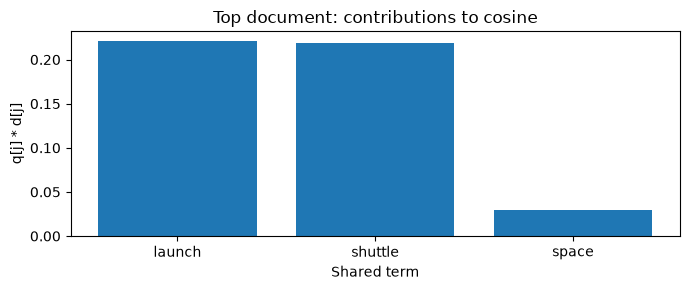

실제 데이터 13설정 대조 시작


| TF | smoothing | norm | 최대 오차 | 어휘 일치 | 통과 |
| --- | --- | --- | --- | --- | --- |
| raw | True | l2 | 1.33e-15 | True | True |
| raw | True | l1 | 3.05e-16 | True | True |
| raw | True | None | 0.00e+00 | True | True |
| log | True | l2 | 3.05e-16 | True | True |
| log | True | l1 | 1.11e-16 | True | True |
| log | True | None | 0.00e+00 | True | True |
| raw | False | l2 | 2.16e-15 | True | True |
| raw | False | l1 | 1.94e-16 | True | True |
| raw | False | None | 0.00e+00 | True | True |
| log | False | l2 | 2.22e-16 | True | True |
| log | False | l1 | 1.11e-16 | True | True |
| log | False | None | 0.00e+00 | True | True |
| binary | True | l2 | 2.22e-16 | True | True |

코사인 sklearn 최대 오차: 5.551115123125783e-17


In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([item[0] for item in ex['shared']], [item[3] for item in ex['shared']])
ax.set(xlabel='Shared term', ylabel='q[j] * d[j]', title='Top document: contributions to cosine')
fig.tight_layout()
plt.show()
plt.close(fig)
print('실제 데이터 13설정 대조 시작')
checks = verify_against_sklearn(corpus.tokens)
table(['TF', 'smoothing', 'norm', '최대 오차', '어휘 일치', '통과'],
      [[r['ours']['tf'], r['ours']['smooth_idf'], r['ours']['norm'],
        format(r['max_error'], '.2e'), r['vocabulary_equal'], r['pass']] for r in checks])
assert all(r['pass'] and r['vocabulary_equal'] for r in checks)
print('코사인 sklearn 최대 오차:', verify_cosine(engine, [actual_query, 'the and of']))

## 8. 성공·실패를 같은 질의 조건에서 보기

어순·부정어 손실은 위에서 직접 확인했다. 다음은 현재 어휘의 동의어·다의어 실험이다.
결과가 다르다고 문서의 의미까지 다르다고 판단하지 않는다. 단어 하나가 여러 뜻을 갖거나
같은 의미가 다른 표기로 나올 때, BoW는 문맥을 복원하지 못한다.
실제 문서의 원인을 단정하지 않고 토큰과 공통 단어로 관찰 가능한 범위만 설명한다.

In [10]:
limits = bow_limits(engine)
table(['사례', '문장 A', '문장 B', '코사인'],
      [[key, limits[key]['a'], limits[key]['b'], round(limits[key]['cosine'], 6)]
       for key in ['word_order', 'negation', 'synonym']])
print('goalie / goaltender 상위 10개 겹침:', limits['synonym']['top10_overlap'])
print('한국어 예는 형태소를 손으로 나눈 별도 실험이다. 이 전처리기의 기능이 아니다.')
for text in ['hockey playoff goalie', 'hockey playoff goaltender', 'save', 'zzzzunknown', 'the and of']:
    results = engine.search(text, topk=3)
    print(repr(text), '토큰', preprocess(text), '→',
          [(h.doc_id, round(h.score, 4), corpus.target_names[corpus.labels[engine.position(h.doc_id)]]) for h in results])

| 사례 | 문장 A | 문장 B | 코사인 |
| --- | --- | --- | --- |
| word_order | the pitcher hit the batter | the batter hit the pitcher | 1.0 |
| negation | this is a good team | this is not a good team | 1.0 |
| synonym | goalie | goaltender | 0.0 |

goalie / goaltender 상위 10개 겹침: 0
한국어 예는 형태소를 손으로 나눈 별도 실험이다. 이 전처리기의 기능이 아니다.
'hockey playoff goalie' 토큰 ['hockey', 'playoff', 'goalie'] → [(4186, 0.372, 'rec.sport.hockey'), (1703, 0.2724, 'rec.sport.hockey'), (3121, 0.2558, 'rec.sport.hockey')]
'hockey playoff goaltender' 토큰 ['hockey', 'playoff', 'goaltender'] → [(1703, 0.2559, 'rec.sport.hockey'), (4576, 0.2129, 'rec.sport.hockey'), (3329, 0.2093, 'rec.sport.baseball')]
'save' 토큰 ['save'] → [(4108, 0.5062, 'rec.sport.baseball'), (3899, 0.3406, 'comp.windows.x'), (1490, 0.2492, 'comp.graphics')]


'zzzzunknown' 토큰 ['zzzzunknown'] → []
'the and of' 토큰 [] → []


## 9. 분류: 표현 학습과 모델 학습을 나누기

원본 공식 train/test 대신 전체 자료를 고정 난수 42의 층화 8:2로 새로 나눈 실험이다.
`X`는 문서×단어, `y`는 문서의 범주 번호다. Test의 새 단어는 열을 추가하지 않는다.
C 선택은 Train 내부 5-fold: 각 fold의 학습 토큰으로 어휘·IDF를 fit하고 검증 토큰은 transform.
C를 고른 뒤 Train 전체로 표현과 모델을 학습하고 Test에서 평가한다.
기존 outputs의 CV는 Train 전체 어휘·IDF를 공유했다. 비교 조건이 바뀌었으므로 별도로 읽는다.

In [11]:
train_idx, test_idx = train_test_indices(corpus.labels)
train_tokens = [corpus.tokens[i] for i in train_idx]
test_tokens = [corpus.tokens[i] for i in test_idx]
classification_vec = TfidfVectorizerNP(min_df=5, max_df=0.5)
X_train = classification_vec.fit_transform(train_tokens)
frozen_idf = classification_vec.idf_.copy()
X_test = classification_vec.transform(test_tokens)
y_train = corpus.labels[train_idx]
y_test = corpus.labels[test_idx]
print('X_train / y_train:', X_train.shape, y_train.shape)
print('X_test / y_test:', X_test.shape, y_test.shape)
print('검색 어휘 / 분류 어휘:', len(engine.vectorizer.terms_), len(classification_vec.terms_))
np.testing.assert_array_equal(frozen_idf, classification_vec.idf_)
assert not set(train_idx).intersection(test_idx)
print('Test의 0벡터 수:', np.count_nonzero(np.linalg.norm(X_test, axis=1) == 0))
# 메모리를 돌려주고 기존 분류 모듈로 같은 분할·설정을 실행한다.
del X_train, X_test
result = run_classification(corpus)
print('fold마다 표현 재학습 CV:', result.cv_scores, '선택 C:', result.C)
print('Test accuracy:', result.accuracy, 'macro F1:', result.f1_macro)
previous = json.loads((root/'outputs/classification.json').read_text(encoding='utf-8'))
print('이전 조건의 저장 결과:', {k: v for k, v in previous.items()
      if k in ['C', 'accuracy', 'f1_macro', 'cv_scores']})

X_train / y_train: (3704, 7357) (3704,)
X_test / y_test: (927, 7357) (927,)
검색 어휘 / 분류 어휘: 8918 7357
Test의 0벡터 수: 0


fold마다 표현 재학습 CV: {1.0: 0.9011929306230314, 10.0: 0.899542174848525, 100.0: 0.895013553532441} 선택 C: 1.0
Test accuracy: 0.8910463861920173 macro F1: 0.8909517165319434
이전 조건의 저장 결과: {'accuracy': 0.9007551240560949, 'f1_macro': 0.9005516220707733, 'C': 10.0, 'cv_scores': {'1.0': 0.9022894052377021, '10.0': 0.9027539452490991, '100.0': 0.8965848181092586}}


## 10. 한 예측과 혼동 행렬 읽기

분류 점수 `z = W @ x + b`를 softmax로 변환한 확률과 검색 코사인은 서로 다르다.
확률의 최댓값이 커도 예측이 맞는다는 보장은 없다. 혼동 행렬은 행=실제, 열=예측, 단위=문서 건수다.

Test 행 / Corpus 위치 / 원래 ID: 0 4038 4309


| 범주 | 선형 점수 | 모델 확률 |
| --- | --- | --- |
| comp.graphics | 0.00261 | 0.19827 |
| comp.windows.x | -0.29628 | 0.14704 |
| rec.sport.baseball | 0.1372 | 0.22683 |
| rec.sport.hockey | 0.05075 | 0.20805 |
| sci.space | 0.10573 | 0.21981 |

실제 / 예측: rec.sport.hockey rec.sport.baseball


| 단어 | 예측−실제 선형 점수 기여 |
| --- | --- |
| shoot | -0.100803 |
| kill | -0.083416 |
| heres | 0.070914 |
| gun | 0.061578 |
| trouble | -0.053437 |
| eddie | 0.053324 |

모든 단어 기여 합 / 절편 차이: -0.05184153438969777 0.13829102595321632
산술적 점수 분해이며 현실의 오분류 원인을 증명하지 않는다.


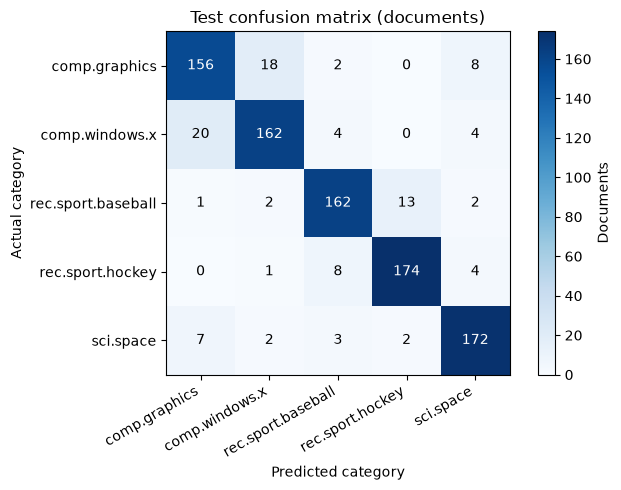

In [12]:
mistakes = np.flatnonzero(result.y_pred != y_test)
row = int(mistakes[0]) if len(mistakes) else 0
x = result.X_test[row]
logits = result.model.coef_ @ x + result.model.intercept_
exp_values = np.exp(logits - logits.max())
probabilities = exp_values / exp_values.sum()
predicted = int(result.y_pred[row])
actual = int(y_test[row])
print('Test 행 / Corpus 위치 / 원래 ID:', row, result.test_idx[row], corpus.doc_ids[result.test_idx[row]])
table(['범주', '선형 점수', '모델 확률'],
      [[name, round(z, 5), round(p, 5)] for name, z, p in zip(corpus.target_names, logits, probabilities)])
np.testing.assert_allclose(probabilities, result.proba[row])
print('실제 / 예측:', corpus.target_names[actual], corpus.target_names[predicted])
push = x * (result.model.coef_[predicted] - result.model.coef_[actual])
intercept_gap = result.model.intercept_[predicted] - result.model.intercept_[actual]
np.testing.assert_allclose(push.sum() + intercept_gap, logits[predicted] - logits[actual], atol=1e-12)
strongest = np.argsort(-np.abs(push))[:6]
table(['단어', '예측−실제 선형 점수 기여'],
      [[result.vectorizer.terms_[j], round(push[j], 6)] for j in strongest if push[j] != 0])
print('모든 단어 기여 합 / 절편 차이:', push.sum(), intercept_gap)
print('산술적 점수 분해이며 현실의 오분류 원인을 증명하지 않는다.')
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(result.confusion, cmap='Blues')
ax.set_xticks(range(5), corpus.target_names, rotation=30, ha='right')
ax.set_yticks(range(5), corpus.target_names)
ax.set(xlabel='Predicted category', ylabel='Actual category', title='Test confusion matrix (documents)')
for i in range(5):
    for j in range(5):
        ax.text(j, i, str(result.confusion[i, j]), ha='center', va='center',
                color='white' if result.confusion[i, j] > result.confusion.max()/2 else 'black')
fig.colorbar(im, ax=ax, label='Documents')
fig.tight_layout()
plt.show()
plt.close(fig)

## 11. 보너스: 점수 방식과 검색 경로는 서로 다른 선택

TF raw/log/double/binary는 반복 단어의 보상을 바꾸고 BM25는 빈도 포화·문서 길이를 반영한다.
역색인은 질의 단어가 있는 문서의 포스팅만 방문하는 경로다. 후보를 찾은 뒤 저장 가중치로
점수를 더한다. TF-IDF와 BM25 점수의 절대 크기를 같은 척도로 비교하지 않는다.

In [13]:
frequency = np.array([[4., 1., 0.]])
for variant in ['raw', 'log', 'double', 'binary']:
    print(variant, term_frequency(frequency, variant))
for method in ['tfidf', 'bm25']:
    full = engine.search(actual_query, method=method)
    indexed = engine.search(actual_query, method=method, use_index=True)
    assert [h.doc_id for h in full] == [h.doc_id for h in indexed]
    np.testing.assert_allclose([h.score for h in full], [h.score for h in indexed])
    print(method, [(h.doc_id, round(h.score, 6)) for h in full])
q = engine.query_vector(actual_query)
weights = {}
for column in np.flatnonzero(q):
    weights[int(column)] = float(q[column])
candidates, candidate_scores, visited = engine.index('tfidf').score(weights)
print('전체 문서:', len(corpus), '후보:', len(candidates), '방문 포스팅:', visited)
# 같은 질의·벡터·행 부분집합으로 측정. 구축/질의 벡터화 제외, 5회 중 최솟값.
timings = benchmark_index(engine, [actual_query, 'hockey playoff goalie', 'save'], [500, len(corpus)])
print(json.dumps(timings, indent=2))
assert all(row['same_top_k'] for row in timings)

raw [[4. 1. 0.]]
log [[2.386294 1.       0.      ]]
double [[1.    0.625 0.   ]]
binary [[1. 1. 0.]]


tfidf [(3165, 0.469254), (279, 0.463842), (4214, 0.45897), (576, 0.439578), (660, 0.436525)]


bm25 [(576, 16.913919), (279, 16.755659), (1174, 16.633212), (3165, 16.087707), (1936, 14.393292)]
전체 문서: 4631 후보: 490 방문 포스팅: 651


[
  {
    "n_docs": 500,
    "n_terms": 8918,
    "full_scan_ms": 1.1079666680113103,
    "column_scan_ms": 0.023333333956543356,
    "index_ms": 0.02676666675445934,
    "index_build_ms": 47.66860000381712,
    "ops_full": 4459000,
    "ops_column": 1166.6666666666667,
    "ops_index": 37.333333333333336,
    "postings_total": 24793,
    "same_top_k": true
  },
  {
    "n_docs": 4631,
    "n_terms": 8918,
    "full_scan_ms": 23.39089999926121,
    "column_scan_ms": 0.149166665020554,
    "index_ms": 0.047833333762052156,
    "index_build_ms": 571.1439000006067,
    "ops_full": 41299258,
    "ops_column": 10805.666666666668,
    "ops_index": 386.6666666666667,
    "postings_total": 220740,
    "same_top_k": true
  }
]


## 친구에게 5분 시연하기

1. `space shuttle launch`의 1위와 겹치는 단어 세 개를 보여 준다. 곱의 합이 코사인임을 설명한다.
2. `the and of`, 미등록 단어를 넣어 빈 결과를 보여 준다. 결과가 없는 이유를 토큰과 어휘에서 찾는다.
3. `space orbit` / `orbit space`, `good team` / `not a good team`으로 잃어버리는 정보를 보인다.
4. `save`를 TF-IDF·BM25로 비교한다. 다의어를 문맥 없이 센다는 한계와 두 점수의 척도 차이를 설명한다.
5. 역색인을 켜도 같은 점수를 얻는지 확인하고, 분류는 정답 범주로 별도 모델을 학습한다는 경계를 짚는다.

```powershell
uv run python main.py --query "space shuttle launch" --explain
uv run python main.py --query "the and of"
uv run python main.py --query "save" --method both --index --topk 3
```

**자기 점검:** space TF=2인데 DF=1인 이유는? 질의에서 fit하면 무엇이 바뀌는가?
0벡터 코사인은 어떻게 처리하는가? Test 단어로 어휘를 확장하면 왜 평가 경계가 흐려지는가?
역색인의 후보 수와 방문 포스팅 수는 왜 다른가? 코사인 0.47을 47% 정답 확률로 읽을 수 있는가?